In [1]:
import re
import random
import numpy as np
import pandas as pd
import emoji
import matplotlib.pyplot as plt
import nltk
nltk.download("words")
from nltk.corpus import words as nltk_words

from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_curve, auc,
                              classification_report, log_loss)
from scipy.sparse import hstack, csr_matrix

np.random.seed(42)
random.seed(42)

ENGLISH_VOCAB = set(w.lower() for w in nltk_words.words())

[nltk_data] Downloading package words to /usr/share/nltk_data...
[nltk_data]   Package words is already up-to-date!


In [2]:
pattern = re.compile(
    r'^(\d{1,2}/\d{1,2}/\d{2}),\s(\d{1,2}:\d{2}\s[AP]M)\s-\s([^:]+):\s(.*)$'
)

def parse_whatsapp_txt(file_path, source_tag):
    with open(file_path, "r", encoding="utf-8") as f:
        raw_lines = f.readlines()

    messages = []
    current = None
    for line in raw_lines:
        line = line.rstrip("\n")
        match = pattern.match(line)
        if match:
            if current:
                messages.append(current)
            date, time, sender, text = match.groups()
            current = {"date": date, "time": time, "sender": sender.strip(),
                       "text": text, "source": source_tag}
        else:
            if current:
                current["text"] += " " + line.strip()
    if current:
        messages.append(current)

    df = pd.DataFrame(messages)
    df = df[~df["text"].str.contains("end-to-end encrypted", na=False)]
    df = df[~df["text"].str.contains("is a contact", na=False)]
    df = df[~df["text"].str.contains(r"<Media omitted>|omitted", case=False, na=False)]
    df = df[df["text"].str.strip() != ""]
    df["sender"] = df["sender"].str.strip()
    return df.reset_index(drop=True)

In [3]:
MAIN_CHAT_PATH = "/kaggle/input/datasets/tasnianawrin123/whatsapp-chat-data/WhatsApp Chat with New Jhumu .txt"  
main_df = parse_whatsapp_txt(MAIN_CHAT_PATH, source_tag="main_chat")

def parse_datetime(row):
    try:
        return pd.to_datetime(f"{row['date']} {row['time']}", format="%m/%d/%y %I:%M %p")
    except Exception:
        return pd.NaT

main_df["datetime"] = main_df.apply(parse_datetime, axis=1)
main_df = main_df.sort_values("datetime").reset_index(drop=True)

print(main_df["sender"].unique())
print(main_df.shape)
print("Unparsed timestamps:", main_df["datetime"].isna().sum())
main_df.head()

['New Jhumu 🔥' 'Nawrin']
(10249, 6)
Unparsed timestamps: 0


,date,time,sender,text,source,datetime
0,8/7/25,9:57 PM,New Jhumu 🔥,Ami jhumu,main_chat,2025-08-07 21:57:00
1,8/7/25,9:58 PM,New Jhumu 🔥,Eta amr wapp number,main_chat,2025-08-07 21:58:00
2,8/7/25,9:58 PM,New Jhumu 🔥,Save diye rakh,main_chat,2025-08-07 21:58:00
3,8/7/25,9:58 PM,Nawrin,As Salamu Alaykum maam,main_chat,2025-08-07 21:58:00
4,8/7/25,9:58 PM,Nawrin,Shuveccha,main_chat,2025-08-07 21:58:00


In [4]:
def get_person_style_stats(main_df, sender):
    texts = main_df[main_df["sender"] == sender]["text"]
    emoji_pool = []
    for t in texts:
        emoji_pool.extend([e["emoji"] for e in emoji.emoji_list(t)])
    return {
        "avg_words": texts.apply(lambda t: len(t.split())).mean(),
        "avg_punct": texts.apply(lambda t: sum(t.count(p) for p in "?!...")).mean(),
        "avg_emoji": texts.apply(lambda t: emoji.emoji_count(t)).mean(),
        "caps_freq": texts.apply(lambda t: any(c.isupper() for c in t)).mean(),
        "emoji_pool": emoji_pool if emoji_pool else ["🙂"],
    }

nawrin_stats = get_person_style_stats(main_df, "Nawrin")
jhumu_stats  = get_person_style_stats(main_df, "New Jhumu 🔥")

# ---- Banglish risk-content templates ----
money_templates = [
    "amar {amount} taka lagbe ekhoni, bkash e pathay dis",
    "ektu {amount} tk dis toh, porey ferot dibo",
    "emergency, {amount} taka lagbe, ei number e pathay dis {number}",
    "amar card ta block hoye gese, ei number e taka pathay dis",
    "bipode asi, {amount} tk lagbe ekhoni, please",
    "tui ki {amount} taka dite parbi ekhon, khub dorkar",
]
location_templates = [
    "ekta kaj ache, {place} e ekta wait korte parbi, ekta lagbe",
    "amar jonno {place} e asha lagbe, ekla asis",
    "{place} er pichone dekha koris, kauke bolish na",
    "ekhoni {place} e asha lagbe, ekla",
    "aj rate {place} e dekha koris, kauke bolish na please",
]
urgency_secrecy_templates = [
    "emergency, ekhoni call dis",
    "eta kauke bolish na please, important",
    "call dis na, ja bolsi shudhu oita kor",
    "eta amader majhe thakuk, family ke bolish na",
    "taratari reply dis, hate time nai",
    "eta dekhar por delete kore dish",
]
phishing_templates = [
    "dekh ei link e tor ekta funny picture post hoise, dhuke dekh",
    "eita dekh, tor account e problem hoise, ei link diye check kor",
    "ekta contest jitse tui, claim korte ei link e click kor",
    "tor picture ekjon misuse korche, ei link e dekh proof",
    "urgent, ei link e giye tor details verify kor nahole account bondho hoye jabe",
]
neutral_impostor_templates = [
    "ki obostha tor aj",
    "assignment ta shesh korsis?",
    "kal koyta bajey dekha korbo amra",
    "gotokal help korar jonno thanks",
    "free hoile janaish",
    "message ta dekhsi, reply dibo",
    "ki kortesish ekhon",
    "khaisish kisu?",
]

amounts = ["500","1000","2000","3000","5000","8000","10000"]
numbers = ["01712345678","01898765432","01611223344"]
places = ["bazar", "purono building", "bus stand ta", "park",
          "school gate", "bridge ta", "khali jaiga ta"]

def fill_template(t):
    return t.format(amount=random.choice(amounts), number=random.choice(numbers),
                     place=random.choice(places))

all_templates = (
    [(t,"money") for t in money_templates] +
    [(t,"location") for t in location_templates] +
    [(t,"urgency") for t in urgency_secrecy_templates] +
    [(t,"phishing") for t in phishing_templates] +
    [(t,"neutral") for t in neutral_impostor_templates]
)

def generate_one_sentence(style, stats=None):
    template, _ = random.choice(all_templates)
    text = fill_template(template) if "{" in template else template
    if style == "generic":
        start = random.choice(["ei", "shun", "acha", "e", ""])
        punct = random.choice(["","!","...","?","!!"])
        text = f"{start} {text}{punct}".strip()
    else:
        if random.random() < min(stats["avg_punct"]/3, 0.8):
            text += random.choice(["!","...","?"])
        if random.random() < min(stats["avg_emoji"], 0.5):
            text += " " + random.choice(stats["emoji_pool"])
        if random.random() < stats["caps_freq"] * 0.3:
            text = text.upper()
    return text

def generate_impostor_window(style, stats=None):
    n_msgs = random.randint(5, 10)
    sentences = []
    for _ in range(n_msgs):
        s = "generic" if (style == "mixed" and random.random() < 0.4) else style
        sentences.append(generate_one_sentence(s if s != "mixed" else "generic", stats))
    return " ".join(sentences)

def generate_impostor_windows(n, style, stats=None):
    return [generate_impostor_window(style, stats) for _ in range(n)]

impostor_windows_generic = generate_impostor_windows(250, "generic")
impostor_windows_nawrin  = generate_impostor_windows(250, "hard", nawrin_stats)
impostor_windows_jhumu   = generate_impostor_windows(250, "hard", jhumu_stats)

impostor_windows_all = impostor_windows_generic + impostor_windows_nawrin + impostor_windows_jhumu
random.shuffle(impostor_windows_all)

print(f"Total impostor windows: {len(impostor_windows_all)}")
print(impostor_windows_all[0])

Total impostor windows: 750
e ki kortesish ekhon acha gotokal help korar jonno thanks... ei ki obostha tor aj!! acha dekh ei link e tor ekta funny picture post hoise, dhuke dekh... shun message ta dekhsi, reply dibo! acha gotokal help korar jonno thanks!!


In [5]:
def build_real_windows(main_df, sender, window_size=8):
    d = main_df[main_df["sender"] == sender].sort_values("datetime")
    texts = d["text"].tolist()
    windows = []
    for i in range(0, len(texts), window_size):
        combined = " ".join(texts[i:i+window_size])
        if len(combined.split()) >= 15:
            windows.append(combined)
    return windows

nawrin_windows = build_real_windows(main_df, "Nawrin")
jhumu_windows  = build_real_windows(main_df, "New Jhumu 🔥")

print(f"Nawrin windows: {len(nawrin_windows)}")
print(f"Jhumu windows : {len(jhumu_windows)}")

Nawrin windows: 600
Jhumu windows : 656


In [6]:
rows = []
for t in nawrin_windows:
    rows.append({"text": t, "sender": "Nawrin"})
for t in jhumu_windows:
    rows.append({"text": t, "sender": "New Jhumu 🔥"})
for t in impostor_windows_all:
    rows.append({"text": t, "sender": "Impostor"})

window_df = pd.DataFrame(rows)
print(window_df.shape)
print(window_df["sender"].value_counts())

(2006, 2)
sender
Impostor       750
New Jhumu 🔥    656
Nawrin         600
Name: count, dtype: int64


In [7]:
def word_count(text):
    words = text.split()
    return len(words) if words else 1

def avg_word_length(text):
    words = text.split()
    return np.mean([len(w) for w in words]) if words else 0

def punctuation_density(text):
    return sum(text.count(p) for p in "?!...") / max(len(text), 1)

def emoji_density(text):
    return emoji.emoji_count(text) / word_count(text)

def informal_word_ratio(text):
    words = [re.sub(r"[^a-zA-Z]", "", w).lower() for w in text.split()]
    words = [w for w in words if w]
    if not words:
        return 0
    return sum(1 for w in words if w not in ENGLISH_VOCAB) / len(words)

def caps_ratio(text):
    letters = [c for c in text if c.isalpha()]
    return sum(1 for c in letters if c.isupper()) / len(letters) if letters else 0

def msg_length(text):
    return len(text)

def contains_risk_keywords(text):
    risk_words = {"taka","tk","bkash","nagad","pathay","lagbe","urgent","bank",
                  "emergency","ekla","eka","dis","bolis","na","link","number","click",
                  "verify","account","claim","kauke","otp","pin","password","pwd"}
    words = set(w.strip(".,!?").lower() for w in text.split())
    return len(words & risk_words) / max(len(words), 1)

def extract_features(text):
    return {
        "word_count": word_count(text),
        "avg_word_len": avg_word_length(text),
        "punct_density": punctuation_density(text),
        "emoji_density": emoji_density(text),
        "informal_ratio": informal_word_ratio(text),
        "caps_ratio": caps_ratio(text),
        "msg_length": msg_length(text),
        "risk_keyword_ratio": contains_risk_keywords(text),
    }

In [8]:
def majority_baseline(y):
    majority_class = y.value_counts().idxmax()
    baseline_acc = (y == majority_class).mean()
    print(f"Majority class: {majority_class}, Baseline accuracy: {baseline_acc:.3f}")
    return baseline_acc

In [9]:
def build_person_window_dataset(window_df, target_sender):
    d = window_df.copy()
    d["label"] = (d["sender"] == target_sender).astype(int)
    return d["text"], d["label"]

def split_dataset(X_text, y, seed=42):
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_text, y, test_size=0.30, stratify=y, random_state=seed)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=seed)
    return X_train, y_train, X_val, y_val, X_test, y_test

In [10]:
def build_features(X_train_text, X_val_text, X_test_text):
    feat_train = X_train_text.apply(extract_features).apply(pd.Series)
    feat_val   = X_val_text.apply(extract_features).apply(pd.Series)
    feat_test  = X_test_text.apply(extract_features).apply(pd.Series)

    scaler = StandardScaler()
    stat_train = scaler.fit_transform(feat_train)
    stat_val   = scaler.transform(feat_val)
    stat_test  = scaler.transform(feat_test)

    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5),
                                  max_features=3000, min_df=2)
    vectorizer.fit(X_train_text)
    tfidf_train = vectorizer.transform(X_train_text)
    tfidf_val   = vectorizer.transform(X_val_text)
    tfidf_test  = vectorizer.transform(X_test_text)

    X_train_full = hstack([csr_matrix(stat_train), tfidf_train]).tocsr()
    X_val_full   = hstack([csr_matrix(stat_val), tfidf_val]).tocsr()
    X_test_full  = hstack([csr_matrix(stat_test), tfidf_test]).tocsr()

    return X_train_full, X_val_full, X_test_full, scaler, vectorizer

In [11]:
from sklearn.utils.class_weight import compute_class_weight
import copy

def train_person_model(window_df, target_sender, epochs=40, patience=5):
    X_text, y = build_person_window_dataset(window_df, target_sender)
    X_train_text, y_train, X_val_text, y_val, X_test_text, y_test = split_dataset(X_text, y)

    print("Baseline check (train set):")
    majority_baseline(y_train)

    X_train_full, X_val_full, X_test_full, scaler, vectorizer = build_features(
        X_train_text, X_val_text, X_test_text)

    model = SGDClassifier(loss="log_loss", penalty="l2", alpha=1e-4, random_state=42)
    classes = np.array([0, 1])

    class_weights = compute_class_weight("balanced", classes=classes, y=y_train)
    weight_map = {classes[0]: class_weights[0], classes[1]: class_weights[1]}
    sample_weights_train = y_train.map(weight_map).values

    train_losses, val_losses, train_accs, val_accs = [], [], [], []

    best_val_acc = -1
    best_epoch = -1
    best_model = None
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.partial_fit(X_train_full, y_train, classes=classes,
                           sample_weight=sample_weights_train)

        train_prob = model.predict_proba(X_train_full)
        val_prob   = model.predict_proba(X_val_full)
        train_loss = log_loss(y_train, train_prob, labels=classes)
        val_loss   = log_loss(y_val, val_prob, labels=classes)
        train_acc  = accuracy_score(y_train, model.predict(X_train_full))
        val_acc    = accuracy_score(y_val, model.predict(X_val_full))

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        # Track best epoch by validation accuracy
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            best_model = copy.deepcopy(model)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Stop early if no improvement for `patience` epochs
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch+1} (best epoch was {best_epoch+1}, "
                  f"best val_acc={best_val_acc:.4f})")
            break

    print(f"Training finished. Best epoch: {best_epoch+1}, Best val_acc: {best_val_acc:.4f}")

    history = {"train_loss": train_losses, "val_loss": val_losses,
               "train_acc": train_accs, "val_acc": val_accs,
               "best_epoch": best_epoch}

    # Return the BEST model (not necessarily the last one)
    return best_model, scaler, vectorizer, history, (X_train_full, y_train), (X_val_full, y_val), (X_test_full, y_test)

In [12]:
nawrin_model, nawrin_scaler, nawrin_vectorizer, nawrin_history, train_set, val_set, test_set = \
    train_person_model(window_df, target_sender="Nawrin")

Baseline check (train set):
Majority class: 0, Baseline accuracy: 0.701
Early stopping at epoch 18 (best epoch was 13, best val_acc=0.9734)
Training finished. Best epoch: 13, Best val_acc: 0.9734


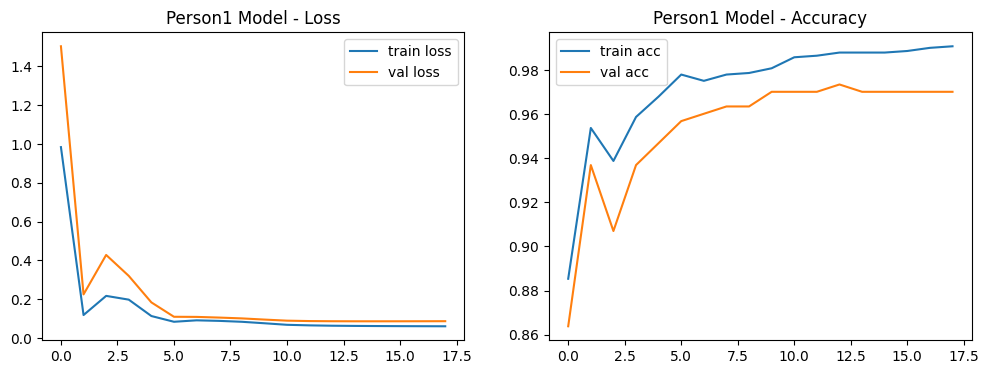

In [13]:
def plot_history_dict(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    ax[0].plot(history["train_loss"], label="train loss")
    ax[0].plot(history["val_loss"], label="val loss")
    ax[0].set_title(f"{title} - Loss"); ax[0].legend()
    ax[1].plot(history["train_acc"], label="train acc")
    ax[1].plot(history["val_acc"], label="val acc")
    ax[1].set_title(f"{title} - Accuracy"); ax[1].legend()
    plt.show()

plot_history_dict(nawrin_history, "Person1 Model")

In [14]:
def evaluate_model(model, test_set, label=""):
    X_test_full, y_test = test_set
    y_prob = model.predict_proba(X_test_full)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    print(f"--- {label} Test Performance ---")
    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
    print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\n", classification_report(y_test, y_pred, zero_division=0))
    return y_test, y_prob

y_test, y_prob = evaluate_model(nawrin_model, test_set, "Person1")

--- Person1 Test Performance ---
Accuracy : 0.973421926910299
Precision: 0.9659090909090909
Recall   : 0.9444444444444444
F1 Score : 0.9550561797752809

Confusion Matrix:
 [[208   3]
 [  5  85]]

               precision    recall  f1-score   support

           0       0.98      0.99      0.98       211
           1       0.97      0.94      0.96        90

    accuracy                           0.97       301
   macro avg       0.97      0.97      0.97       301
weighted avg       0.97      0.97      0.97       301



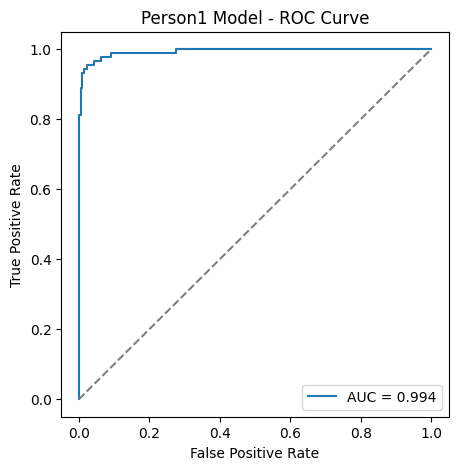

In [15]:
def plot_roc(y_test, y_prob, title):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(5,5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0,1],[0,1],"--", color="gray")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"{title} - ROC Curve"); plt.legend()
    plt.show()

plot_roc(y_test, y_prob, "Person1 Model")

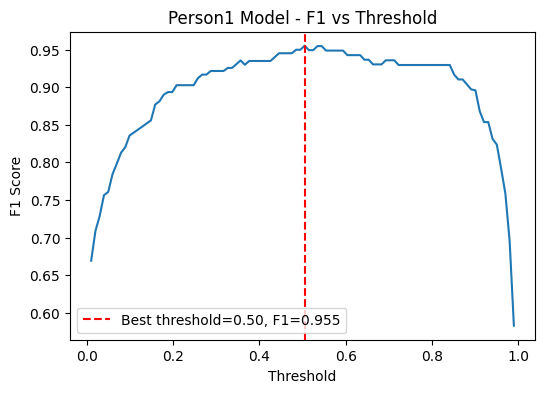

In [16]:
def plot_f1_curve(y_test, y_prob, title):
    thresholds = np.linspace(0.01, 0.99, 100)
    f1_scores = [f1_score(y_test, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
    best_idx = np.argmax(f1_scores)
    plt.figure(figsize=(6,4))
    plt.plot(thresholds, f1_scores)
    plt.axvline(thresholds[best_idx], color="red", linestyle="--",
                label=f"Best threshold={thresholds[best_idx]:.2f}, F1={f1_scores[best_idx]:.3f}")
    plt.xlabel("Threshold"); plt.ylabel("F1 Score")
    plt.title(f"{title} - F1 vs Threshold"); plt.legend()
    plt.show()

plot_f1_curve(y_test, y_prob, "Person1 Model")

Baseline check (train set):
Majority class: 0, Baseline accuracy: 0.673
Early stopping at epoch 24 (best epoch was 19, best val_acc=0.9468)
Training finished. Best epoch: 19, Best val_acc: 0.9468


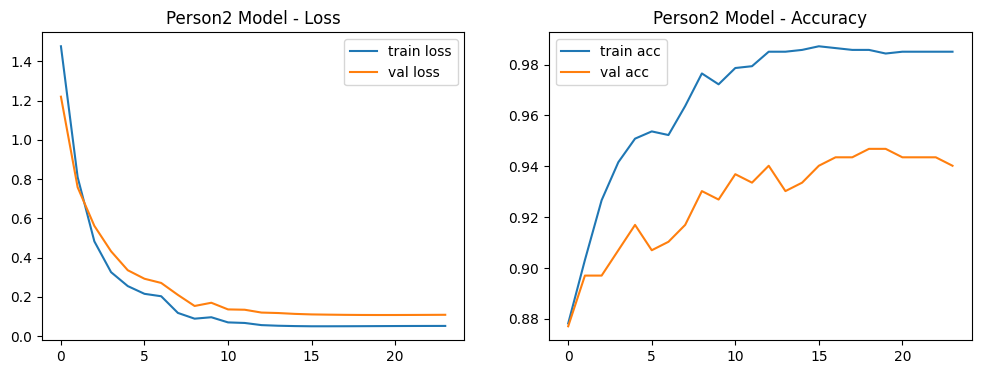

--- Person2 Test Performance ---
Accuracy : 0.9534883720930233
Precision: 0.9375
Recall   : 0.9183673469387755
F1 Score : 0.9278350515463918

Confusion Matrix:
 [[197   6]
 [  8  90]]

               precision    recall  f1-score   support

           0       0.96      0.97      0.97       203
           1       0.94      0.92      0.93        98

    accuracy                           0.95       301
   macro avg       0.95      0.94      0.95       301
weighted avg       0.95      0.95      0.95       301



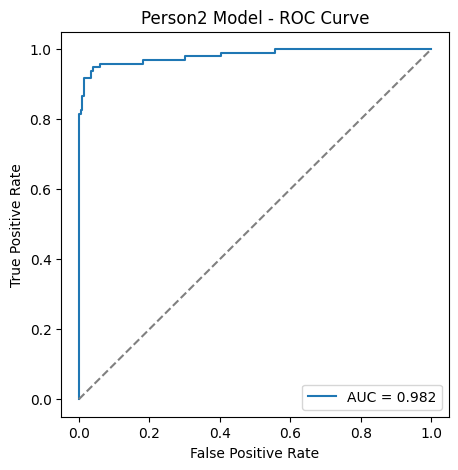

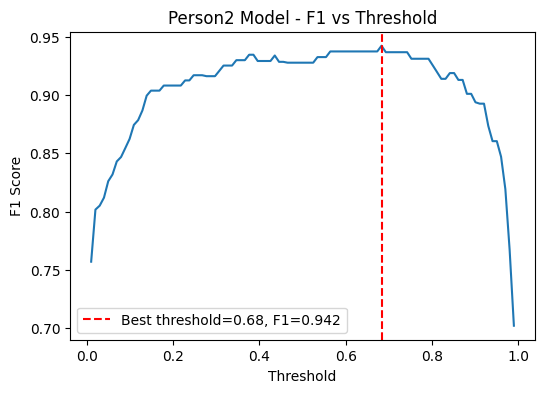

In [17]:
jhumu_model, jhumu_scaler, jhumu_vectorizer, jhumu_history, jtrain_set, jval_set, jtest_set = \
    train_person_model(window_df, target_sender="New Jhumu 🔥")

plot_history_dict(jhumu_history, "Person2 Model")
y_test_j, y_prob_j = evaluate_model(jhumu_model, jtest_set, "Person2")
plot_roc(y_test_j, y_prob_j, "Person2 Model")
plot_f1_curve(y_test_j, y_prob_j, "Person2 Model")

In [18]:
def evaluate_by_subgroup(model, X_test_text, y_test, test_source_labels, scaler, vectorizer, label=""):
    # Rebuild test features (same pipeline as training)
    feat_test = X_test_text.apply(extract_features).apply(pd.Series)
    stat_test = scaler.transform(feat_test)
    tfidf_test = vectorizer.transform(X_test_text)
    X_test_full = hstack([csr_matrix(stat_test), tfidf_test]).tocsr()

    y_prob = model.predict_proba(X_test_full)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    results_df = pd.DataFrame({
        "true_label": y_test.values,
        "pred_label": y_pred,
        "source": test_source_labels.values
    })

    print(f"--- {label}: Accuracy by subgroup ---")
    for source_type in results_df["source"].unique():
        subset = results_df[results_df["source"] == source_type]
        acc = (subset["true_label"] == subset["pred_label"]).mean()
        print(f"{source_type:20s} n={len(subset):4d}  accuracy={acc:.3f}")

In [19]:
# Rebuild train/val/test split WITH source labels attached, so we can group by it
def build_person_window_dataset_with_source(window_df, target_sender):
    d = window_df.copy()
    d["label"] = (d["sender"] == target_sender).astype(int)
    d["source_type"] = d["sender"].apply(lambda s: "impostor" if s == "Impostor" else "real_other")
    d.loc[d["sender"] == target_sender, "source_type"] = "real_target"
    return d["text"], d["label"], d["source_type"]

X_text_n, y_n, source_n = build_person_window_dataset_with_source(window_df, "Nawrin")

X_train_n, X_temp_n, y_train_n, y_temp_n, src_train_n, src_temp_n = train_test_split(
    X_text_n, y_n, source_n, test_size=0.30, stratify=y_n, random_state=42)
X_val_n, X_test_n, y_val_n, y_test_n, src_val_n, src_test_n = train_test_split(
    X_temp_n, y_temp_n, src_temp_n, test_size=0.50, stratify=y_temp_n, random_state=42)

evaluate_by_subgroup(nawrin_model, X_test_n, y_test_n, src_test_n,
                      nawrin_scaler, nawrin_vectorizer, "Person1 Model")

--- Person1 Model: Accuracy by subgroup ---
real_target          n=  90  accuracy=0.944
impostor             n= 124  accuracy=1.000
real_other           n=  87  accuracy=0.966


In [20]:
X_text_j, y_j, source_j = build_person_window_dataset_with_source(window_df, "New Jhumu 🔥")

X_train_j, X_temp_j, y_train_j, y_temp_j, src_train_j, src_temp_j = train_test_split(
    X_text_j, y_j, source_j, test_size=0.30, stratify=y_j, random_state=42)
X_val_j, X_test_j, y_val_j, y_test_j, src_val_j, src_test_j = train_test_split(
    X_temp_j, y_temp_j, src_temp_j, test_size=0.50, stratify=y_temp_j, random_state=42)

evaluate_by_subgroup(jhumu_model, X_test_j, y_test_j, src_test_j,
                      jhumu_scaler, jhumu_vectorizer, "Person2 Model")

--- Person2 Model: Accuracy by subgroup ---
real_target          n=  98  accuracy=0.918
real_other           n=  92  accuracy=0.935
impostor             n= 111  accuracy=1.000


In [21]:
human_impersonation_jhumu = [
    "kire amake age bolisnai keno",
    "eta tomar vai k gie bolo",
    "mone thake naki haradin khali mathai nur ghure",
    "tomake ageo na korsilam ami",
    "azk ki tor id hack hoisilo?",
    "tomar bestie ke dekhlam seidin",
    "ar valo lage na",
    "amar kalke 3ta quiz",
    "nuruddin bolsilo jomo akta pooso",
    "e number e 5000tk pathaile apnar account ta active hoe jabe abar",
    "Imraan amra neela market kobe jacchi",
    "ok date and time fix kore amk janaw",
    "ei page ta follow dio https:456trubdj/89y",
    "I am on diet , tmi kintu amk thamaba",
    "tumi amke bkash koro",
    "ammu jailer r ami ashami",
    "eita kothay? eto soothing",
    "link e dhukley tk dicche",
    "cholo sremangal jai",
    "sobai k raji koraw, semester break a jawa jay",
    "Hello!",
    "Are you there? Its urgent!!!",
    "Tumar bkash e taka hobe?",
    "Around 4-5k",
    "Dite parba please ami sunday tei back kortesi...",
    "Pathaiso???",
    "Hea taka ashes",
    "Thank youuuu bondhuuuuuuu",
    "Ami sunday tei back dissi",
    "Ki khobor?",
    "Kire raiga asosss kn",
    "Mair dibo",
    "Aro mair khawa baki ase tr",
    "Ki hoise dost",
    "Allah maf koruk",
    "Na cashout charge lagbe na kono",
    "Sure eta? Abr check dio",
    "Amader value lagbe",
    "Ki bolsilam vule gesi",
    "Na tumi bujhonai",
    "Tanaka kal ektu 11 tar dike chata canteen thakis. Ami toder jonno cake banaisilam",
    "Tui ki koshto paisos? Ami kintu ovabe bolinai",
    "Bbu ekta help korte parbi?",
    "Do react and comment in the main post",
    "Kichu hoise bbu?",
    "O khoda",
    "Ei dekh ACS e tor ekta funny picture post hoise..ei link tay dhuke dekh",
    "Jinish ta etto nice. Amar cousin onek pochondo krse",
    "Na ami ashole erkom tone ey kotha boli toh",
    "Tanaka tumi ki ajke kuril diye bashay jaba? Amar jonno kuril rail line shamne ektu wait korte parba? Ekta kaj ache",
    "Nasiba asish?",
    "Klk Tor class sesh kokhn?",
    "Chol fuchka khabo.",
    "Ei eita ki pretty.",
    "01****5**12 ei number e bkash koro",
    "Nasiba tui Valo hobi na.",
    "Is everything okay?",
    "Ei tora kothai?",
    "Ay shobai ak shathe jai",
    "Accha tahole to report e extra kisu dite hobe na tai nah!",
]

human_impersonation_nawrin = [
    "Ayoo kotto cutu vaii",
    "Accha shuno tumi ar Ami ak din jai oi place e.",
    "Emergency 5K tk Bkash kor dst... porshu diye dibo",
    "Nasiba tui 5 tai boshundhora te ashte parbi?",
    "Amar help lagbe. Tui just Ami jei area bolbo oi khane jabi Ami ashbo oi khane.",
    "Nasibaa vallage na.",
    "Gossip dao.",
    "Dst 01****5**12 ei number e 2K tk de...emergency",
    "Dst tor kache ekta link disi dekh....eta te click kor",
    "Oh Jano ajke ki hoese?",
    "Dst klk tor class koyta theke koyta?",
    "Tui ki campus e? Dekha koro babu",
    "Babu bhallage na",
    "Dst ei link e dhuke 4200 ei otp de",
    "Ami ekta notun drama dekhtesi 👉👈",
    "Gemini re diya dekh edi solve korte pare kina",
    "Tanaka tor kase 2000 taka dhar hobe? Ami ekta problem e porsi.",
    "Tor baki course gulay kemon grade ashche?",
    "Toke ekta link dicchi ektu id password diye login kore fill up kore dis toh",
    "Amr puran kahini mone pore regret hoitese 😑",
    "Ami d er groud faculty lift er shamne asi",
    "Dst mundir aunty er tong er piche ashis",
    "Dst amar new number 01****56** e 500 tk recharge kor...ekhoni lagbe",
    "Nasiba K-drama dekhba cholo. Tumi toh free aso.",
    "Jhomo Ekta help lagbe. 1000tk dite parbi? Amar ektu lagbe emergency. Toke Ami campus e diye dibo Kal diye dibo",
    "Taile ki sir ke dibo, naki?",
    "Er jnno mainshere bujhano laage na je kaaj pari",
    "Hala y uzbuk ekta",
    "Dhong maray khali beta",
    "Prothom din e toh bollam link e dhuka lagbe",
    "Ami in shaa Allah faculty hoile amio emne question korum",
    "Ami shara din bisanay pora",
    "Vai table formatting niyeo toh genjam lagtese, bkash e tk de chatgpt premium kini",
    "Ghumay gesilam laptop shbkisu khola raikha",
    "Vai... 1tay brush paste mukh e nisi.. 1:44 e mukh dhuilam",
    "Ei link ta te dhuk",
    "Ovaga jedike chaay... Sagor shukaye jaay",
    "Ghum ashe jhumuuuu",
    "Phone diya slide ber korse.. Koy eto chhoto keno, chol shobai mile tk uthaye onake laptop kine dei",
    "R toke editor access disi ektu link tate dhuke dekh",
    "Sarar er pwd ta de",
    "Emneo tomar jamai nai... Eto daily daily bassidi jawa lagbo na",
    "Vid gula dekh... Note e ja likhsi oigulai",
    "ei supo koi re",
    "Bhai ajke ki assignment korchis?",
    "kalke ki varsity jabi",
    "Kalke dekha korish kichu kotha ache",
    "shun na amay ekta help korte parbi khob urgent chilo",
    "amar urgent kicu tk lagto 3k moto dhar dite parbi? 👀",
    "ami pore diye dibo beshi question korish nah",
    "Tui ekhon ki online a ? tui online a thakle ekhon dite parbi dstt details pore bolbo niii",
    "accha dsttt online a ashle amar reply dish toh",
    "tui ki khabar khaisos raat e",
    "Mon kharap koiro na. Bhalomoto exam deo. Er porer semester e bhalo korbi In Shaa Allah",
    "Tore class e dekhlam na. koi bhondami kortesili",
    "Apatoto egulo pora sesh. Kisu lagle bolish",
    "Tumar ki ucb bank e account ase ?",
    "Transfer money kora jay na onno bank e?",
    "Accha ei Account No. 15328946xxxxxx e dekho to tranfer hoy ki na?",
    "Tahole to jei sensor e load beshi sheigulo battery er sathe add korbo...",
]

print(f"Person1 impersonation messages: {len(human_impersonation_nawrin)}")
print(f"Person2 impersonation messages: {len(human_impersonation_jhumu)}")

# Reduced window_size from 8 to 4 for this test specifically — this gives more
# windows from the same message count, which stabilizes the "% fooled" result.
def build_human_test_windows(texts, window_size=4):
    windows = []
    for i in range(0, len(texts), window_size):
        combined = " ".join(texts[i:i+window_size])
        if len(combined.split()) >= 10:   # lowered slightly since windows are smaller now
            windows.append(combined)
    return windows

human_windows_jhumu  = build_human_test_windows(human_impersonation_jhumu, window_size=4)
human_windows_nawrin = build_human_test_windows(human_impersonation_nawrin, window_size=4)

print(f"Human impersonation windows (Person1): {len(human_windows_nawrin)}")
print(f"Human impersonation windows (Person2): {len(human_windows_jhumu)}")

Person1 impersonation messages: 60
Person2 impersonation messages: 60
Human impersonation windows (Person1): 15
Human impersonation windows (Person2): 15


In [22]:
def test_against_human_impersonation(model, scaler, vectorizer, human_windows, label=""):
    if len(human_windows) == 0:
        print(f"No human impersonation windows to test for {label}.")
        return
    texts_series = pd.Series(human_windows)
    feat = texts_series.apply(extract_features).apply(pd.Series)
    stat = scaler.transform(feat)
    tfidf = vectorizer.transform(texts_series)
    X_full = hstack([csr_matrix(stat), tfidf]).tocsr()

    y_prob = model.predict_proba(X_full)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    fooled = y_pred.sum()
    print(f"--- {label}: Human Impersonation Test ---")
    print(f"Total windows: {len(y_pred)}")
    print(f"Model fooled (predicted as real target): {fooled} ({fooled/len(y_pred)*100:.1f}%)")
    print(f"Correctly flagged as NOT real: {len(y_pred)-fooled} ({(1-fooled/len(y_pred))*100:.1f}%)")
    print(f"Probabilities: {np.round(y_prob, 3)}")

test_against_human_impersonation(nawrin_model, nawrin_scaler, nawrin_vectorizer,
                                  human_windows_nawrin, "Person1 Model")
print()
test_against_human_impersonation(jhumu_model, jhumu_scaler, jhumu_vectorizer,
                                  human_windows_jhumu, "Person2 Model")

--- Person1 Model: Human Impersonation Test ---
Total windows: 15
Model fooled (predicted as real target): 12 (80.0%)
Correctly flagged as NOT real: 3 (20.0%)
Probabilities: [0.879 0.989 0.972 0.299 0.853 0.983 0.667 0.685 0.96  0.991 0.999 0.03
 0.37  0.941 0.788]

--- Person2 Model: Human Impersonation Test ---
Total windows: 15
Model fooled (predicted as real target): 7 (46.7%)
Correctly flagged as NOT real: 8 (53.3%)
Probabilities: [0.672 0.07  0.689 0.996 0.944 0.    0.    0.933 0.505 0.46  0.022 0.062
 0.912 0.    0.068]


In [23]:
def diagnose_fooled_windows(human_windows, model, scaler, vectorizer, label=""):
    texts_series = pd.Series(human_windows)
    feat = texts_series.apply(extract_features).apply(pd.Series)
    stat = scaler.transform(feat)
    tfidf = vectorizer.transform(texts_series)
    X_full = hstack([csr_matrix(stat), tfidf]).tocsr()

    y_prob = model.predict_proba(X_full)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    print(f"--- {label}: Fooled window breakdown ---")
    for i, (text, prob, pred) in enumerate(zip(human_windows, y_prob, y_pred)):
        risk_score = feat.iloc[i]["risk_keyword_ratio"]
        flag = "FOOLED" if pred == 1 else "caught"
        print(f"[{flag}] style_prob={prob:.3f}  risk_ratio={risk_score:.3f}  text={text[:80]}...")

diagnose_fooled_windows(human_windows_nawrin, nawrin_model, nawrin_scaler, nawrin_vectorizer, "Person1")
print()
diagnose_fooled_windows(human_windows_jhumu, jhumu_model, jhumu_scaler, jhumu_vectorizer, "Person2")

--- Person1: Fooled window breakdown ---
[FOOLED] style_prob=0.879  risk_ratio=0.094  text=Ayoo kotto cutu vaii Accha shuno tumi ar Ami ak din jai oi place e. Emergency 5K...
[FOOLED] style_prob=0.989  risk_ratio=0.154  text=Amar help lagbe. Tui just Ami jei area bolbo oi khane jabi Ami ashbo oi khane. N...
[FOOLED] style_prob=0.972  risk_ratio=0.080  text=Dst tor kache ekta link disi dekh....eta te click kor Oh Jano ajke ki hoese? Dst...
[caught] style_prob=0.299  risk_ratio=0.115  text=Babu bhallage na Dst ei link e dhuke 4200 ei otp de Ami ekta notun drama dekhtes...
[FOOLED] style_prob=0.853  risk_ratio=0.103  text=Tanaka tor kase 2000 taka dhar hobe? Ami ekta problem e porsi. Tor baki course g...
[FOOLED] style_prob=0.983  risk_ratio=0.094  text=Ami d er groud faculty lift er shamne asi Dst mundir aunty er tong er piche ashi...
[FOOLED] style_prob=0.667  risk_ratio=0.088  text=Jhomo Ekta help lagbe. 1000tk dite parbi? Amar ektu lagbe emergency. Toke Ami ca...
[FOOLED] style_prob=0

In [24]:
def combined_decision(text_windows, model, scaler, vectorizer, style_threshold=0.5, risk_threshold=0.05):
    """
    Flags a window as 'anomaly' (not the real person / risky) if EITHER:
    - the style model says it's NOT the target person (style_prob < style_threshold), OR
    - the risk-keyword ratio is high enough to independently signal danger,
      REGARDLESS of how well the style matches.

    Note: this means even a PERFECT style mimic gets flagged if they ask for
    money/links/location — which is the actual goal of a safety system like this.
    """
    texts_series = pd.Series(text_windows)
    feat = texts_series.apply(extract_features).apply(pd.Series)
    stat = scaler.transform(feat)
    tfidf = vectorizer.transform(texts_series)
    X_full = hstack([csr_matrix(stat), tfidf]).tocsr()

    style_prob = model.predict_proba(X_full)[:, 1]
    risk_ratio = feat["risk_keyword_ratio"].values

    style_says_not_them = style_prob < style_threshold
    content_says_risky = risk_ratio >= risk_threshold

    final_flag = style_says_not_them | content_says_risky   # OR logic
    return final_flag, style_prob, risk_ratio

def evaluate_combined(text_windows, model, scaler, vectorizer, label="", risk_threshold=0.05):
    flags, style_prob, risk_ratio = combined_decision(
        text_windows, model, scaler, vectorizer, risk_threshold=risk_threshold)

    total = len(flags)
    caught = flags.sum()
    still_fooled = total - caught

    print(f"--- {label}: Combined (Style + Risk-Content) Detection ---")
    print(f"Total windows: {total}")
    print(f"Correctly flagged (style OR content triggered): {caught} ({caught/total*100:.1f}%)")
    print(f"Still fooled (neither triggered): {still_fooled} ({still_fooled/total*100:.1f}%)")

evaluate_combined(human_windows_nawrin, nawrin_model, nawrin_scaler, nawrin_vectorizer, "Person1")
print()
evaluate_combined(human_windows_jhumu, jhumu_model, jhumu_scaler, jhumu_vectorizer, "Person2")

--- Person1: Combined (Style + Risk-Content) Detection ---
Total windows: 15
Correctly flagged (style OR content triggered): 14 (93.3%)
Still fooled (neither triggered): 1 (6.7%)

--- Person2: Combined (Style + Risk-Content) Detection ---
Total windows: 15
Correctly flagged (style OR content triggered): 11 (73.3%)
Still fooled (neither triggered): 4 (26.7%)


In [25]:
import joblib
joblib.dump(nawrin_model, "/kaggle/working/nawrin_model.pkl")
joblib.dump(nawrin_scaler, "/kaggle/working/nawrin_scaler.pkl")
joblib.dump(nawrin_vectorizer, "/kaggle/working/nawrin_vectorizer.pkl")

joblib.dump(jhumu_model, "/kaggle/working/jhumu_model.pkl")
joblib.dump(jhumu_scaler, "/kaggle/working/jhumu_scaler.pkl")
joblib.dump(jhumu_vectorizer, "/kaggle/working/jhumu_vectorizer.pkl")

['/kaggle/working/jhumu_vectorizer.pkl']

In [26]:
from sklearn.svm import OneClassSVM

def train_oneclass_from_split(X_train_text, src_train, target_sender, nu=0.1):
    real_target_train_texts = X_train_text[src_train == "real_target"].reset_index(drop=True)

    feat_train = real_target_train_texts.apply(extract_features).apply(pd.Series)
    scaler = StandardScaler()
    stat_train = scaler.fit_transform(feat_train)

    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), max_features=3000, min_df=1)
    vectorizer.fit(real_target_train_texts)
    tfidf_train = vectorizer.transform(real_target_train_texts)

    X_train_full = hstack([csr_matrix(stat_train), tfidf_train]).tocsr()

    model = OneClassSVM(kernel="rbf", nu=nu, gamma="scale")
    model.fit(X_train_full)

    print(f"[{target_sender}] One-class model trained on {len(real_target_train_texts)} real_target training windows.")
    return model, scaler, vectorizer

In [27]:
nawrin_oc_model, nawrin_oc_scaler, nawrin_oc_vectorizer = \
    train_oneclass_from_split(X_train_n, src_train_n, "Nawrin")

jhumu_oc_model, jhumu_oc_scaler, jhumu_oc_vectorizer = \
    train_oneclass_from_split(X_train_j, src_train_j, "New Jhumu 🔥")

[Nawrin] One-class model trained on 420 real_target training windows.
[New Jhumu 🔥] One-class model trained on 459 real_target training windows.


In [28]:
def transform_with_oc(texts, scaler, vectorizer):
    texts = pd.Series(texts).reset_index(drop=True)
    feat = texts.apply(extract_features).apply(pd.Series)
    stat = scaler.transform(feat)
    tfidf = vectorizer.transform(texts)
    return hstack([csr_matrix(stat), tfidf]).tocsr()

def binary_style_only_accuracy(model, scaler, vectorizer, texts, correct_label, threshold=0.5):
    if len(texts) == 0:
        return None
    X = transform_with_oc(texts, scaler, vectorizer)
    probs = model.predict_proba(X)[:, 1]
    preds = (probs >= threshold).astype(int)
    return (preds == correct_label).mean() * 100

def binary_combined_group_accuracy(model, scaler, vectorizer, texts, correct_label,
                                     style_threshold=0.5, risk_threshold=0.05):
    if len(texts) == 0:
        return None
    flags, _, _ = combined_decision(texts, model, scaler, vectorizer,
                                     style_threshold=style_threshold, risk_threshold=risk_threshold)
    preds = (~flags).astype(int)   # not flagged = predicted as target (1)
    return (preds == correct_label).mean() * 100

def compare_on_shared_test_set(X_test_text, src_test,
                                bin_model, bin_scaler, bin_vectorizer,
                                oc_model, oc_scaler, oc_vectorizer,
                                human_windows, label=""):
    print(f"\n=== {label}: Binary vs. One-Class ===")
    print(f"{'Group':30s} {'Bin style-only':>15s} {'Bin combined':>15s} {'One-Class':>12s}")

    for group_name in ["real_target", "real_other", "impostor"]:
        group_texts = X_test_text[src_test == group_name]
        correct_label = 1 if group_name == "real_target" else 0

        style_acc = binary_style_only_accuracy(bin_model, bin_scaler, bin_vectorizer, group_texts, correct_label)
        combined_acc = binary_combined_group_accuracy(bin_model, bin_scaler, bin_vectorizer, group_texts, correct_label)

        oc_X = transform_with_oc(group_texts, oc_scaler, oc_vectorizer)
        if group_name == "real_target":
            oc_acc = (oc_model.predict(oc_X) == 1).mean() * 100
        else:
            oc_acc = (oc_model.predict(oc_X) == -1).mean() * 100

        display_name = f"{group_name} ({'accept' if group_name=='real_target' else 'reject'})"
        print(f"{display_name:30s} {style_acc:14.1f}% {combined_acc:14.1f}% {oc_acc:11.1f}%")

    style_acc = binary_style_only_accuracy(bin_model, bin_scaler, bin_vectorizer, human_windows, correct_label=0)
    combined_acc = binary_combined_group_accuracy(bin_model, bin_scaler, bin_vectorizer, human_windows, correct_label=0)
    oc_X_human = transform_with_oc(human_windows, oc_scaler, oc_vectorizer)
    oc_acc = (oc_model.predict(oc_X_human) == -1).mean() * 100
    print(f"{'human_impersonation (reject)':30s} {style_acc:14.1f}% {combined_acc:14.1f}% {oc_acc:11.1f}%")
    #print("* separate external test set (Cell 22), not part of the main train/test split")

compare_on_shared_test_set(X_test_n, src_test_n,
                            nawrin_model, nawrin_scaler, nawrin_vectorizer,
                            nawrin_oc_model, nawrin_oc_scaler, nawrin_oc_vectorizer,
                            human_windows_nawrin, "Person1")

compare_on_shared_test_set(X_test_j, src_test_j,
                            jhumu_model, jhumu_scaler, jhumu_vectorizer,
                            jhumu_oc_model, jhumu_oc_scaler, jhumu_oc_vectorizer,
                            human_windows_jhumu, "Person2")


=== Person1: Binary vs. One-Class ===
Group                           Bin style-only    Bin combined    One-Class
real_target (accept)                     94.4%           84.4%        81.1%
real_other (reject)                      96.6%           97.7%        27.6%
impostor (reject)                       100.0%          100.0%       100.0%
human_impersonation (reject)             20.0%           93.3%        80.0%

=== Person2: Binary vs. One-Class ===
Group                           Bin style-only    Bin combined    One-Class
real_target (accept)                     91.8%           82.7%        86.7%
real_other (reject)                      93.5%           93.5%        35.9%
impostor (reject)                       100.0%          100.0%       100.0%
human_impersonation (reject)             53.3%           73.3%        60.0%


In [29]:
joblib.dump(nawrin_oc_model, "/kaggle/working/nawrin_oneclass_model.pkl")
joblib.dump(nawrin_oc_scaler, "/kaggle/working/nawrin_oneclass_scaler.pkl")
joblib.dump(nawrin_oc_vectorizer, "/kaggle/working/nawrin_oneclass_vectorizer.pkl")

joblib.dump(jhumu_oc_model, "/kaggle/working/jhumu_oneclass_model.pkl")
joblib.dump(jhumu_oc_scaler, "/kaggle/working/jhumu_oneclass_scaler.pkl")
joblib.dump(jhumu_oc_vectorizer, "/kaggle/working/jhumu_oneclass_vectorizer.pkl")

print("One-class models saved.")

One-class models saved.


In [30]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

In [31]:
def plot_confusion_matrix_custom(cm, labels, title):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=True, values_format='d')
    ax.set_title(title, fontsize=13, fontweight='bold', pad=15)
    fig.subplots_adjust(top=0.85, right=0.95)
    plt.tight_layout()
    plt.show()

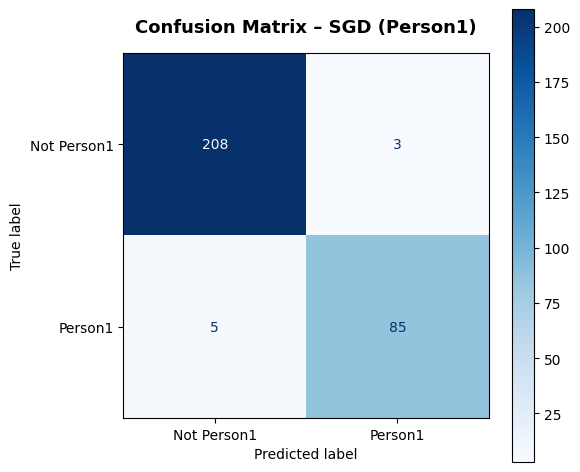

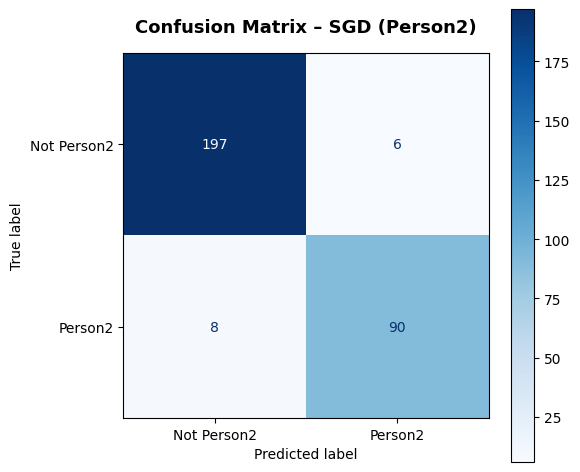

In [32]:
def get_sgd_confusion_matrix(model, scaler, vectorizer, X_test_text, y_test, threshold=0.5):
    X = transform_with_oc(X_test_text, scaler, vectorizer)
    probs = model.predict_proba(X)[:, 1]
    preds = (probs >= threshold).astype(int)
    return confusion_matrix(y_test, preds)

cm_nawrin_sgd = get_sgd_confusion_matrix(nawrin_model, nawrin_scaler, nawrin_vectorizer, X_test_n, y_test_n)
plot_confusion_matrix_custom(cm_nawrin_sgd, ["Not Person1", "Person1"], "Confusion Matrix – SGD (Person1)")

cm_jhumu_sgd = get_sgd_confusion_matrix(jhumu_model, jhumu_scaler, jhumu_vectorizer, X_test_j, y_test_j)
plot_confusion_matrix_custom(cm_jhumu_sgd, ["Not Person2", "Person2"], "Confusion Matrix – SGD (Person2)")

--- Person1 One-Class SVM Test Performance ---
Accuracy : 0.7342
Precision: 0.5368
Recall   : 0.8111
F1 Score : 0.6460

Confusion Matrix:
 [[148  63]
 [ 17  73]]

               precision    recall  f1-score   support

  Not Target       0.90      0.70      0.79       211
      Target       0.54      0.81      0.65        90

    accuracy                           0.73       301
   macro avg       0.72      0.76      0.72       301
weighted avg       0.79      0.73      0.75       301



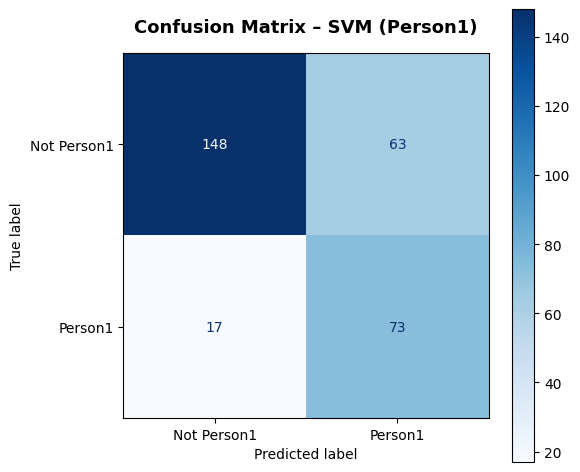

--- Person2 One-Class SVM Test Performance ---
Accuracy : 0.7608
Precision: 0.5903
Recall   : 0.8673
F1 Score : 0.7025

Confusion Matrix:
 [[144  59]
 [ 13  85]]

               precision    recall  f1-score   support

  Not Target       0.92      0.71      0.80       203
      Target       0.59      0.87      0.70        98

    accuracy                           0.76       301
   macro avg       0.75      0.79      0.75       301
weighted avg       0.81      0.76      0.77       301



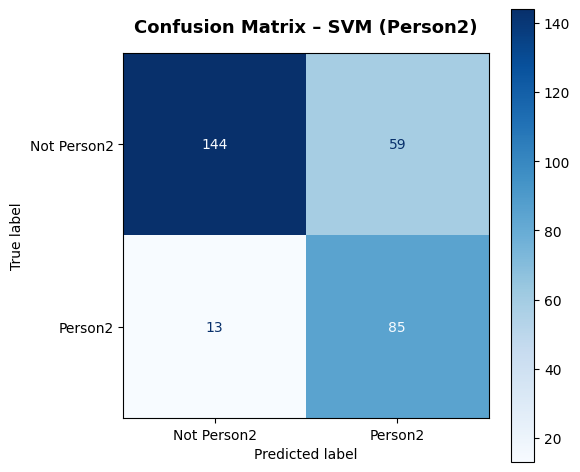

In [33]:
def evaluate_oneclass_full(oc_model, oc_scaler, oc_vectorizer, X_test_text, y_test, label=""):
    X_test_full = transform_with_oc(X_test_text, oc_scaler, oc_vectorizer)
    raw_pred = oc_model.predict(X_test_full)             # +1 = inlier (target), -1 = outlier
    y_pred = (raw_pred == 1).astype(int)
    decision_scores = oc_model.decision_function(X_test_full)  # continuous score, higher = more target-like

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    print(f"--- {label} One-Class SVM Test Performance ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print("\nConfusion Matrix:\n", cm)
    print("\n", classification_report(y_test, y_pred, zero_division=0, target_names=["Not Target","Target"]))

    return y_test, decision_scores, cm

y_test_oc_n, scores_oc_n, cm_nawrin_oc = evaluate_oneclass_full(
    nawrin_oc_model, nawrin_oc_scaler, nawrin_oc_vectorizer, X_test_n, y_test_n, "Person1")
plot_confusion_matrix_custom(cm_nawrin_oc, ["Not Person1", "Person1"], "Confusion Matrix – SVM (Person1)")

y_test_oc_j, scores_oc_j, cm_jhumu_oc = evaluate_oneclass_full(
    jhumu_oc_model, jhumu_oc_scaler, jhumu_oc_vectorizer, X_test_j, y_test_j, "Person2")
plot_confusion_matrix_custom(cm_jhumu_oc, ["Not Person2", "Person2"], "Confusion Matrix – SVM (Person2)")

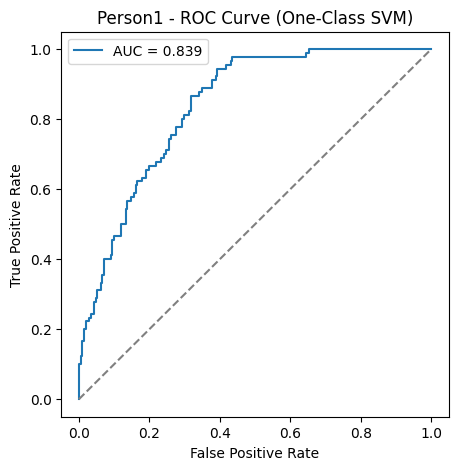

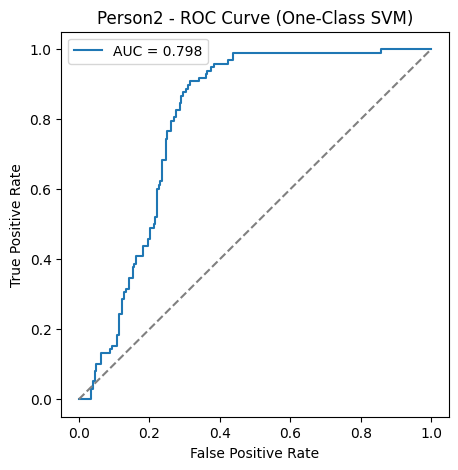

In [34]:
def plot_oc_roc(y_test, decision_scores, title):
    fpr, tpr, _ = roc_curve(y_test, decision_scores)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(5,5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0,1],[0,1],"--", color="gray")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"{title} - ROC Curve (One-Class SVM)"); plt.legend()
    plt.show()

plot_oc_roc(y_test_oc_n, scores_oc_n, "Person1")
plot_oc_roc(y_test_oc_j, scores_oc_j, "Person2")

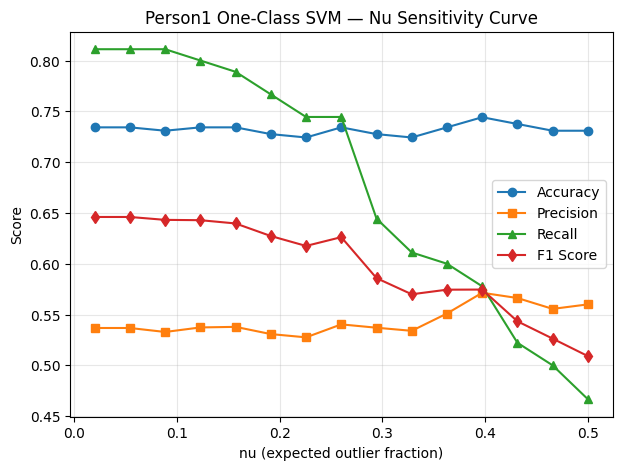

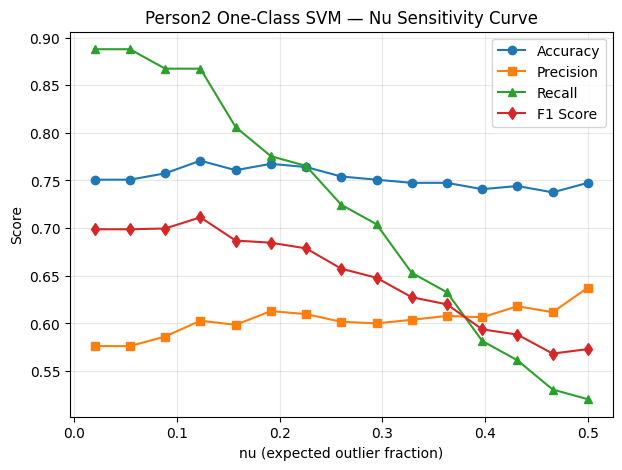

In [35]:
def nu_sensitivity_curve(X_train_text, src_train, X_test_text, y_test, label=""):
    nu_values = np.linspace(0.02, 0.5, 15)
    accs, precs, recs, f1s = [], [], [], []

    real_target_train_texts = X_train_text[src_train == "real_target"].reset_index(drop=True)
    feat_train = real_target_train_texts.apply(extract_features).apply(pd.Series)
    scaler = StandardScaler()
    stat_train = scaler.fit_transform(feat_train)
    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5), max_features=3000, min_df=1)
    vectorizer.fit(real_target_train_texts)
    tfidf_train = vectorizer.transform(real_target_train_texts)
    X_train_full = hstack([csr_matrix(stat_train), tfidf_train]).tocsr()

    for nu in nu_values:
        m = OneClassSVM(kernel="rbf", nu=nu, gamma="scale")
        m.fit(X_train_full)
        X_test_full = transform_with_oc(X_test_text, scaler, vectorizer)
        y_pred = (m.predict(X_test_full) == 1).astype(int)
        accs.append(accuracy_score(y_test, y_pred))
        precs.append(precision_score(y_test, y_pred, zero_division=0))
        recs.append(recall_score(y_test, y_pred, zero_division=0))
        f1s.append(f1_score(y_test, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(nu_values, accs, label="Accuracy", marker='o')
    plt.plot(nu_values, precs, label="Precision", marker='s')
    plt.plot(nu_values, recs, label="Recall", marker='^')
    plt.plot(nu_values, f1s, label="F1 Score", marker='d')
    plt.xlabel("nu (expected outlier fraction)")
    plt.ylabel("Score")
    plt.title(f"{label} One-Class SVM — Nu Sensitivity Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

nu_sensitivity_curve(X_train_n, src_train_n, X_test_n, y_test_n, "Person1")
nu_sensitivity_curve(X_train_j, src_train_j, X_test_j, y_test_j, "Person2")

In [36]:
def oc_combined_decision(texts, oc_model, oc_scaler, oc_vectorizer, risk_threshold=0.05):
    texts_series = pd.Series(texts).reset_index(drop=True)
    feat = texts_series.apply(extract_features).apply(pd.Series)
    X = transform_with_oc(texts_series, oc_scaler, oc_vectorizer)

    style_says_outlier = (oc_model.predict(X) == -1)
    content_says_risky = (feat["risk_keyword_ratio"].values >= risk_threshold)

    final_flag = style_says_outlier | content_says_risky   # True = flagged as NOT target/anomaly
    return final_flag

def oc_combined_group_accuracy(oc_model, oc_scaler, oc_vectorizer, texts, correct_label, risk_threshold=0.05):
    if len(texts) == 0:
        return None
    flags = oc_combined_decision(texts, oc_model, oc_scaler, oc_vectorizer, risk_threshold=risk_threshold)
    preds = (~flags).astype(int)   # not flagged = predicted target (1)
    return (preds == correct_label).mean() * 100

def compare_full_symmetric(X_test_text, src_test,
                            bin_model, bin_scaler, bin_vectorizer,
                            oc_model, oc_scaler, oc_vectorizer,
                            human_windows, label=""):
    print(f"\n=== {label}: Fully Symmetric Comparison (Style-only vs Combined, both models) ===")
    print(f"{'Group':30s} {'SGD style':>11s} {'SGD combined':>13s} {'OC style':>10s} {'OC combined':>13s}")

    def get_group_texts(group_name):
        if group_name == "human_impersonation":
            return human_windows
        return X_test_text[src_test == group_name]

    for group_name in ["real_target", "real_other", "impostor", "human_impersonation"]:
        group_texts = get_group_texts(group_name)
        correct_label = 1 if group_name == "real_target" else 0

        sgd_style = binary_style_only_accuracy(bin_model, bin_scaler, bin_vectorizer, group_texts, correct_label)
        sgd_comb = binary_combined_group_accuracy(bin_model, bin_scaler, bin_vectorizer, group_texts, correct_label)

        oc_X = transform_with_oc(group_texts, oc_scaler, oc_vectorizer)
        if group_name == "real_target":
            oc_style = (oc_model.predict(oc_X) == 1).mean() * 100
        else:
            oc_style = (oc_model.predict(oc_X) == -1).mean() * 100
        oc_comb = oc_combined_group_accuracy(oc_model, oc_scaler, oc_vectorizer, group_texts, correct_label)

        display_name = f"{group_name} ({'accept' if group_name=='real_target' else 'reject'})"
        print(f"{display_name:30s} {sgd_style:10.1f}% {sgd_comb:12.1f}% {oc_style:9.1f}% {oc_comb:12.1f}%")

compare_full_symmetric(X_test_n, src_test_n,
                        nawrin_model, nawrin_scaler, nawrin_vectorizer,
                        nawrin_oc_model, nawrin_oc_scaler, nawrin_oc_vectorizer,
                        human_windows_nawrin, "Person1")

compare_full_symmetric(X_test_j, src_test_j,
                        jhumu_model, jhumu_scaler, jhumu_vectorizer,
                        jhumu_oc_model, jhumu_oc_scaler, jhumu_oc_vectorizer,
                        human_windows_jhumu, "Person2")


=== Person1: Fully Symmetric Comparison (Style-only vs Combined, both models) ===
Group                            SGD style  SGD combined   OC style   OC combined
real_target (accept)                 94.4%         84.4%      81.1%         74.4%
real_other (reject)                  96.6%         97.7%      27.6%         34.5%
impostor (reject)                   100.0%        100.0%     100.0%        100.0%
human_impersonation (reject)         20.0%         93.3%      80.0%         93.3%

=== Person2: Fully Symmetric Comparison (Style-only vs Combined, both models) ===
Group                            SGD style  SGD combined   OC style   OC combined
real_target (accept)                 91.8%         82.7%      86.7%         79.6%
real_other (reject)                  93.5%         93.5%      35.9%         38.0%
impostor (reject)                   100.0%        100.0%     100.0%        100.0%
human_impersonation (reject)         53.3%         73.3%      60.0%         60.0%


In [43]:
print("Person1 real messages:", (main_df["sender"] == "Nawrin").sum())
print("Person2 real messages:", (main_df["sender"] == "New Jhumu 🔥").sum())
print("Expected windows (no filtering), Person1:", (main_df["sender"] == "Nawrin").sum() // 8 + 1)
print("Expected windows (no filtering), Person2:", (main_df["sender"] == "New Jhumu 🔥").sum() // 8 + 1)
print("Actual windows built, Person1:", len(nawrin_windows))
print("Actual windows built, Person2:", len(jhumu_windows))

Person1 real messages: 4826
Person2 real messages: 5423
Expected windows (no filtering), Person1: 604
Expected windows (no filtering), Person2: 678
Actual windows built, Person1: 600
Actual windows built, Person2: 656


In [44]:
print("Person1 vectorizer vocabulary size:", len(nawrin_vectorizer.vocabulary_))
print("Person2 vectorizer vocabulary size:", len(jhumu_vectorizer.vocabulary_))

Person1 vectorizer vocabulary size: 3000
Person2 vectorizer vocabulary size: 3000
